# 04 · Clima y topografía por polígono — Reto AgroCebada 2026

## Qué hace este cuaderno
Convierte los rásteres de clima (lluvia mensual, temperatura mínima y máxima, 2022–2025) y de terreno (elevación y pendiente) en números por parcela. Dos ideas lo hacen riguroso: **(1) cada valor es un promedio exacto ponderado por área sobre el polígono de la parcela**, nunca el valor en su punto central, y **(2) el clima se suma o se promedia en las etapas del propio cultivo de cada parcela** (las ventanas encontradas en el cuaderno 03), no en meses fijos del calendario.

## Por qué el polígono y no el punto central
La auditoría encontró tres parcelas cuyo centro cae en un píxel de pendiente sin dato y 31 parcelas que abarcan dos o tres píxeles climáticos. Un punto central ignora el resto de la parcela y, peor aún, puede caer en un hueco. Aquí el valor de cada parcela es el promedio de los píxeles que toca, **cada píxel ponderado por la fracción exacta del área de la parcela que cae en él**, calculada recortando el polígono con cada píxel (sin aproximaciones). Los píxeles sin dato se excluyen y se registra la fracción de la parcela con datos válidos.

## Por qué las etapas del propio cultivo
La lluvia de agosto importa mucho para una parcela que florece en agosto y mucho menos para una que florece en octubre. Con las fechas de cada parcela del cuaderno 03 calculamos lluvia, temperatura, demanda evaporativa y balance hídrico en los 60 días previos a la siembra, en las etapas temprana, media (floración) y tardía (llenado de grano) y en toda la temporada. Los valores mensuales se reparten en cada ventana en proporción a los días de cada mes que cubre.

## Limitaciones
Los rásteres de clima tienen píxeles de ~5 km, así que las 197 parcelas comparten solo unos 25 píxeles climáticos. Por eso el clima dice sobre todo *dónde* está una parcela (lo que la referencia de ubicación ya sabe). Se vuelve propio de cada parcela sobre todo a través de sus fechas de temporada: dos vecinas sembradas con un mes de diferencia reciben lluvias distintas. El terreno, a 120 m, sí varía entre parcelas vecinas.

## Pasos
| Paso | Qué |
|---|---|
| A | Extracción exacta ponderada por área: método y validación |
| B | Clima mensual por parcela (48 meses × 3 variables) y el contexto climático de 2025 |
| C | Clima en las etapas del cultivo de cada parcela: lluvia, Tmáx, Tmín, Tmedia, amplitud térmica, evapotranspiración de Hargreaves, balance hídrico y grados-día; anomalías de 2025 frente a 2022–2024 |
| D | Terreno: elevación, pendiente (ráster provisto + recalculada desde la elevación como contraste), orientación (exposición norte y este) y posición topográfica |
| E | Integrar, documentar, mirada descriptiva al rendimiento y reporte |

## Entradas
Rásteres en `raw/` (`PREC_*`, `Tmin_*`, `Tmax_*`, `Elevacion_*`, `Pendiente_*`), `interim/plots.parquet` (cuaderno 01), `features/phenology_dates.parquet` (cuaderno 03), `interim/labels.parquet` (solo en la última celda).

## Salidas
| Archivo | Contenido |
|---|---|
| `interim/climate_monthly_plot.parquet` | por parcela × mes (2022–2025): precipitación, Tmín, Tmáx y fracción de área válida |
| `features/climate_features.parquet`, `features/topo_features.parquet` | una fila por parcela |
| `features/feature_catalog_nb04.csv` | documentación de cada variable |
| `qa/nb04_*`, `qa/figures/nb04_*`, `qa/nb04_report.md` | verificaciones, figuras y reporte |

**Tiempo de ejecución:** unos 2–4 minutos.

## 0 · Preparación

In [1]:
!pip install -q rasterio

In [2]:
# 0.1 · Librerías, Drive y rutas
import os, re, json, math, time, warnings
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
from scipy import ndimage
import matplotlib
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

BASE = Path("/content/drive/MyDrive/AgroCebada") if IN_COLAB else Path(os.environ.get("AGC_BASE", "AgroCebada"))
RAW, INTERIM, FEATURES, QA = BASE / "raw", BASE / "interim", BASE / "features", BASE / "qa"
FIG = QA / "figures"
for d in [FEATURES, FIG]:
    d.mkdir(parents=True, exist_ok=True)
for f in [INTERIM / "plots.parquet", FEATURES / "phenology_dates.parquet"]:
    assert f.exists(), f"Falta {f}: ejecuta primero los cuadernos 01 y 03."

SEED = 42
RNG = np.random.default_rng(SEED)
YEAR = 2025
CRS_MX = "EPSG:6372"
if "display" not in globals():
    display = print
print(f"BASE = {BASE} | Colab: {IN_COLAB}")

Mounted at /content/drive
BASE = /content/drive/MyDrive/AgroCebada | Colab: True


In [3]:
# 0.2 · Configuración fija
PRE_DAYS = 60                 # ventana previa a la siembra: humedad del suelo al establecimiento
T_BASE = 0.0                  # temperatura base de los grados-día de la cebada (°C)
TPI_RADII_PX = {"tpi_1km": 4, "tpi_4km": 16}   # posición topográfica: elevación menos la media de un cuadrado de (2k+1) píxeles (píxeles de 120 m)
TOPO_BUFFER_M = 5000          # el terreno se lee para el rectángulo de las parcelas + 5 km
NODATA_FLOOR = -1000          # todo valor por debajo de este se trata como sin dato

COLORS = {"2025": "#2a78d6", "2022–2024": "#9a9a94", "tmax": "#eb6834", "tmin": "#2a78d6"}
MUNI_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
GREY, RED, INK = "#9a9a94", "#e34948", "#2b2b28"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5df", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#b8b7ae", "axes.labelcolor": INK, "xtick.color": "#6b6b66",
                     "ytick.color": "#6b6b66", "font.size": 9, "legend.frameon": False})

CHECKS, CATALOG = [], []
def check(name, ok, detail="", warn_only=True, info=False):
    status = "INFO" if info else ("PASS" if ok else ("WARN" if warn_only else "FAIL"))
    rec = {"check": name, "status": status, "detail": str(detail)}
    for j, r in enumerate(CHECKS):
        if r["check"] == name:
            CHECKS[j] = rec
            break
    else:
        CHECKS.append(rec)
    print(f"[{status}] {name}" + (f" — {detail}" if detail != "" else ""))

def register(name, group, source, var, window, stat, description, unit="", use=True):
    CATALOG.append(dict(feature=name, group=group, sensor=source, index=var, window=window, statistic=stat,
                        unit=unit, description=description, use_in_model=use))

In [4]:
# 0.3 · Encontrar los rásteres en raw/ (gana la primera copia de cada archivo; el NB01 verificó que no hay duplicados en conflicto)
RASTERS = {"prec": {}, "tmin": {}, "tmax": {}}
TOPO = {}
for p in sorted(RAW.rglob("*.tif")):
    low = p.name.lower()
    m = re.match(r"(prec|tmin|tmax)_(\d{4})_(\d{2})\.tif$", low)
    if m:
        RASTERS[m.group(1)].setdefault((int(m.group(2)), int(m.group(3))), p)
    elif "elev" in low:
        TOPO.setdefault("elevation", p)
    elif "pend" in low or "slope" in low:
        TOPO.setdefault("slope", p)
MONTHS = [(y, m) for y in range(2022, 2026) for m in range(1, 13)]
for v in RASTERS:
    missing = [k for k in MONTHS if k not in RASTERS[v]]
    assert not missing, f"{v}: faltan los meses {missing[:4]}"
assert {"elevation", "slope"} <= set(TOPO), "no se encontraron los rásteres de elevación o pendiente"
print({v: len(d) for v, d in RASTERS.items()}, {k: p.name for k, p in TOPO.items()})

{'prec': 48, 'tmin': 48, 'tmax': 48} {'elevation': 'Elevacion_INEGI_CEM4_120m.tif', 'slope': 'Pendiente_INEGI_CEM4_120m_grados.tif'}


In [5]:
# 0.4 · Polígonos de las parcelas (geográficos y métricos) y fechas de temporada
import geopandas as gpd
import rasterio
from rasterio.windows import from_bounds, Window

plots = gpd.read_parquet(INTERIM / "plots.parquet").sort_values("ID_POLIGONO").reset_index(drop=True)
IDS = plots.ID_POLIGONO.tolist()

def rings_of(geom):
    """[(exterior, [huecos]), ...] como listas de (x, y) sin el vértice de cierre."""
    polys = [geom] if geom.geom_type == "Polygon" else list(geom.geoms)
    return [([tuple(c[:2]) for c in p.exterior.coords[:-1]], [[tuple(c[:2]) for c in h.coords[:-1]] for h in p.interiors])
            for p in polys]

RINGS_GEO = [rings_of(g) for g in plots.geometry]
RINGS_MX = [rings_of(g) for g in plots.to_crs(CRS_MX).geometry]
BOUNDS_MX = plots.to_crs(CRS_MX).total_bounds

def read_raster(path, bounds=None):
    """Banda 1 como arreglo de flotantes con NaN donde no hay dato, más su malla (a, c, e, f) y su tamaño.
    bounds = (xmin, ymin, xmax, ymax) en el SRC del ráster lee solo esa ventana."""
    with rasterio.open(path) as src:
        if bounds is None:
            arr, T = src.read(1, masked=True), src.transform
        else:
            w0 = from_bounds(*bounds, transform=src.transform)
            win = Window(int(math.floor(w0.col_off)), int(math.floor(w0.row_off)),
                         int(math.ceil(w0.width)) + 1, int(math.ceil(w0.height)) + 1)
            arr, T = src.read(1, window=win, masked=True, boundless=True), src.window_transform(win)
        assert abs(T.b) < 1e-12 and abs(T.d) < 1e-12, "no se admiten rásteres rotados"
        a = np.ma.filled(arr.astype("float64"), np.nan)
        a[a < NODATA_FLOOR] = np.nan
        return a, (T.a, T.c, T.e, T.f), src.crs.to_epsg()

ph = pd.read_parquet(FEATURES / "phenology_dates.parquet").set_index("ID_POLIGONO").reindex(IDS)
for c in ["sos", "center", "eos", "mid_start", "mid_end"]:
    ph[c] = pd.to_datetime(ph[c])
print(f"{len(IDS)} parcelas; fechas de temporada para {int(ph.sos.notna().sum())}")

197 parcelas; fechas de temporada para 197


## 1 · Paso A: extracción exacta ponderada por área

**Cómo funciona.** Para cada parcela y cada píxel del ráster que toca, el polígono se recorta con el cuadrado del píxel (recorte de Sutherland–Hodgman) y se mide el área del pedazo recortado (fórmula del área de Gauss). El **peso** del píxel es esa área dividida entre el área de la parcela, así que los pesos de una parcela suman 1. El valor de la parcela es entonces

$$\text{valor} = \frac{\sum_i w_i\,x_i}{\sum_{i\ \text{válido}} w_i}, \qquad \text{fracción válida} = \sum_{i\ \text{válido}} w_i$$

donde se omiten los píxeles sin dato. Una fracción válida menor que 1 indica que parte de la parcela cayó en datos faltantes.

**Validación.** Antes de usarlo verificamos (1) que los pesos de cada parcela sumen 1 y (2) en 10 parcelas al azar, que los pesos coincidan con una estimación por fuerza bruta: se lanzan ~500,000 puntos dentro de la parcela y se cuenta cuántos caen en cada píxel.

In [6]:
# 1.1 · Cobertura exacta de un polígono sobre la malla de un ráster
def _clip(pts, axis, bound, keep_ge):
    out, n = [], len(pts)
    for i in range(n):
        P, Q = pts[i], pts[(i + 1) % n]
        pin = P[axis] >= bound if keep_ge else P[axis] <= bound
        qin = Q[axis] >= bound if keep_ge else Q[axis] <= bound
        if pin:
            out.append(P)
        if pin != qin:
            t = (bound - P[axis]) / (Q[axis] - P[axis])
            out.append((P[0] + t * (Q[0] - P[0]), P[1] + t * (Q[1] - P[1])))
    return out

def _area(pts):
    if len(pts) < 3:
        return 0.0
    s = 0.0
    for i in range(len(pts)):
        (x1, y1), (x2, y2) = pts[i], pts[(i + 1) % len(pts)]
        s += x1 * y2 - x2 * y1
    return abs(s) / 2

def _ring_in_box(ring, xmin, ymin, xmax, ymax):
    pts = ring
    for axis, b, ge in ((0, xmin, True), (0, xmax, False), (1, ymin, True), (1, ymax, False)):
        pts = _clip(pts, axis, b, ge)
        if not pts:
            return 0.0
    return _area(pts)

def coverage(parts, grid, width, height):
    """Píxeles que toca un polígono y la fracción de su área en cada uno. grid = (a, c, e, f): x = c + col·a, y = f + fila·e."""
    a, c, e, f = grid
    total = sum(_area(ext) - sum(_area(h) for h in holes) for ext, holes in parts)
    xs = [p[0] for ext, _ in parts for p in ext]
    ys = [p[1] for ext, _ in parts for p in ext]
    c0, c1 = max(int(math.floor((min(xs) - c) / a)), 0), min(int(math.floor((max(xs) - c) / a)), width - 1)
    r0, r1 = max(int(math.floor((max(ys) - f) / e)), 0), min(int(math.floor((min(ys) - f) / e)), height - 1)
    R, Cl, W = [], [], []
    for r in range(r0, r1 + 1):
        ymax = f + r * e
        ymin = ymax + e
        for col in range(c0, c1 + 1):
            xmin = c + col * a
            A = sum(_ring_in_box(ext, xmin, ymin, xmin + a, ymax) - sum(_ring_in_box(h, xmin, ymin, xmin + a, ymax) for h in holes)
                    for ext, holes in parts)
            if A > 0:
                R.append(r); Cl.append(col); W.append(A / total)
    return np.array(R, int), np.array(Cl, int), np.array(W, float)

def weighted(arr, cov):
    """Media ponderada por área sobre los píxeles válidos y fracción válida de la parcela."""
    R, Cl, W = cov
    v = arr[R, Cl]
    ok = np.isfinite(v)
    share = W[ok].sum()
    return (float((W[ok] * v[ok]).sum() / share) if share > 0 else np.nan), float(share)

In [7]:
# 1.2 · Validación: los pesos suman 1 y coinciden con un conteo de puntos por fuerza bruta
from matplotlib.path import Path as MplPath
clim_arr, CLIM_GRID, clim_epsg = read_raster(RASTERS["prec"][(YEAR, 1)])
H, Wd = clim_arr.shape
assert clim_epsg == 4326, "se esperaban rásteres de clima en EPSG:4326"
COV_CLIM = [coverage(r, CLIM_GRID, Wd, H) for r in RINGS_GEO]
sums = np.array([w.sum() for _, _, w in COV_CLIM])
check("Los pesos de cobertura de cada parcela suman 1 (malla climática)", bool(np.allclose(sums, 1, atol=1e-5)),
      f"min {sums.min():.6f}, max {sums.max():.6f}", warn_only=False)
n_pix = pd.Series([len(w) for _, _, w in COV_CLIM]).value_counts().sort_index()
check("Parcelas que abarcan varios píxeles climáticos", True, "; ".join(f"{k} píxel(es): {v} parcelas" for k, v in n_pix.items()), info=True)

def brute_force(parts, grid, n=700):
    a, c, e, f = grid
    ext = parts[0][0]
    xs, ys = [p[0] for p in ext], [p[1] for p in ext]
    X, Y = np.meshgrid(np.linspace(min(xs), max(xs), n), np.linspace(min(ys), max(ys), n))
    pts = np.c_[X.ravel(), Y.ravel()]
    inside = MplPath(np.array(ext)).contains_points(pts)
    for h in parts[0][1]:
        inside &= ~MplPath(np.array(h)).contains_points(pts)
    col = np.floor((pts[inside, 0] - c) / a).astype(int)
    row = np.floor((pts[inside, 1] - f) / e).astype(int)
    s = pd.Series(1.0, index=pd.MultiIndex.from_arrays([row, col])).groupby(level=[0, 1]).sum()
    return s / s.sum()

# una malla de prueba fina (≈ 120 m en grados) para que cada parcela abarque muchos píxeles: una prueba exigente del recorte
errs = []
for i in RNG.choice(len(IDS), 10, replace=False):
    ext = RINGS_GEO[i][0][0]
    g = (0.0011, min(p[0] for p in ext) - 0.0007, -0.0011, max(p[1] for p in ext) + 0.0005)
    R, Cl, W = coverage(RINGS_GEO[i], g, 400, 400)
    exact = pd.Series(W, index=pd.MultiIndex.from_arrays([R, Cl]))
    j = pd.concat([exact, brute_force(RINGS_GEO[i], g)], axis=1).fillna(0)
    errs.append(float((j[0] - j[1]).abs().max()))
check("Los pesos exactos coinciden con un conteo de puntos por fuerza bruta (10 parcelas, malla fina)", max(errs) < 0.005,
      f"mayor diferencia en la fracción de cualquier píxel: {max(errs):.4f}", warn_only=False)

[PASS] Los pesos de cobertura de cada parcela suman 1 (malla climática) — min 1.000000, max 1.000000
[INFO] Parcelas que abarcan varios píxeles climáticos — 1 píxel(es): 166 parcelas; 2 píxel(es): 29 parcelas; 3 píxel(es): 2 parcelas
[PASS] Los pesos exactos coinciden con un conteo de puntos por fuerza bruta (10 parcelas, malla fina) — mayor diferencia en la fracción de cualquier píxel: 0.0010


## 2 · Paso B: clima mensual por parcela

48 meses × 3 variables (precipitación CHIRPS en mm/mes; temperatura mínima y máxima diaria media CHIRTS-ERA5 en °C), cada una como promedio ponderado por área sobre la parcela. Los pesos de cobertura se calculan una vez por malla y se reutilizan en todos los meses.

In [8]:
# 2.1 · Extracción
grid_cache = {}
rows = []
t0 = time.time()
for v in ["prec", "tmin", "tmax"]:
    for (y, m) in MONTHS:
        arr, grid, _ = read_raster(RASTERS[v][(y, m)])
        key = tuple(round(x, 9) for x in grid) + arr.shape
        if key not in grid_cache:
            grid_cache[key] = [coverage(r, grid, arr.shape[1], arr.shape[0]) for r in RINGS_GEO]
        for pid, cov in zip(IDS, grid_cache[key]):
            val, share = weighted(arr, cov)
            rows.append((pid, y, m, v, val, share))
clim = pd.DataFrame(rows, columns=["ID_POLIGONO", "year", "month", "var", "value", "valid_share"])
CM = clim.pivot_table(index=["ID_POLIGONO", "year", "month"], columns="var", values="value").reset_index()
CM["valid_share_min"] = clim.groupby(["ID_POLIGONO", "year", "month"]).valid_share.min().to_numpy()
CM.to_parquet(INTERIM / "climate_monthly_plot.parquet", index=False)
print(f"{len(grid_cache)} malla(s) climática(s) distinta(s); {CM.shape} en {time.time() - t0:.0f} s")
check("Clima: todas las parcelas por completo en píxeles válidos, todos los meses", bool((CM.valid_share_min > 0.999).all() and CM[["prec", "tmin", "tmax"]].notna().all().all()),
      f"fracción válida mínima {CM.valid_share_min.min():.3f}")
key = (CM.year == YEAR) & CM.month.between(4, 10)
p_aprOct = CM[key].groupby("ID_POLIGONO").prec.sum()
check("Precipitación abr–oct 2025 por parcela plausible (150–1500 mm)", bool(p_aprOct.between(150, 1500).all()),
      f"{p_aprOct.min():.0f}–{p_aprOct.max():.0f} mm (puntos centrales del NB01: 703–1459 mm)")
n_distinct = CM[key].groupby("ID_POLIGONO").prec.sum().round(1).nunique()
check("Número efectivo de situaciones climáticas distintas", True,
      f"{n_distinct} totales distintos de lluvia abr–oct 2025 entre 197 parcelas", info=True)

2 malla(s) climática(s) distinta(s); (9456, 7) en 44 s
[PASS] Clima: todas las parcelas por completo en píxeles válidos, todos los meses — fracción válida mínima 1.000
[PASS] Precipitación abr–oct 2025 por parcela plausible (150–1500 mm) — 703–1459 mm (puntos centrales del NB01: 703–1459 mm)
[INFO] Número efectivo de situaciones climáticas distintas — 53 totales distintos de lluvia abr–oct 2025 entre 197 parcelas


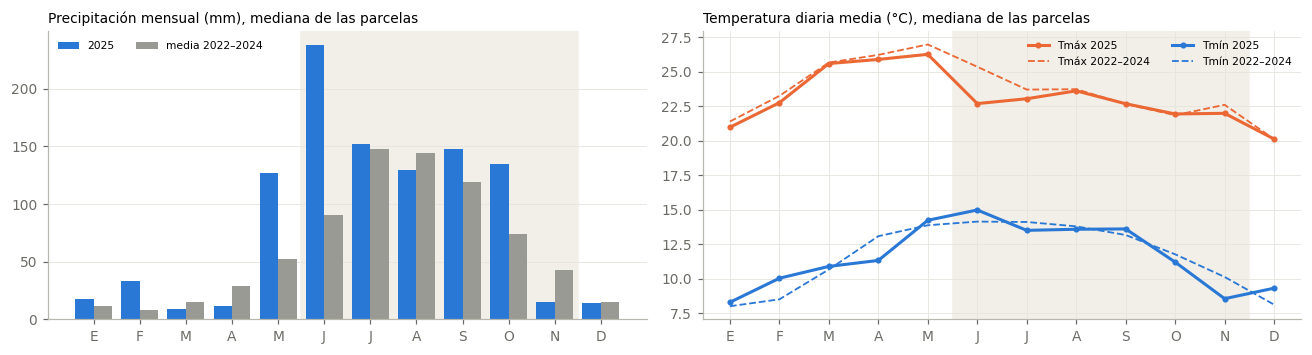

month        1     2     3     4      5      6      7      8      9      10    11    12
2025       18.0  33.0   9.0  12.0  127.0  238.0  152.0  129.0  147.0  135.0  15.0  15.0
2022–2024  12.0   8.0  15.0  29.0   52.0   91.0  148.0  144.0  119.0   74.0  42.0  15.0


In [9]:
# 2.2 · Figura: la temporada 2025 en su contexto climático (mediana de las parcelas)
med = CM.groupby(["year", "month"])[["prec", "tmin", "tmax"]].median().reset_index()
now = med[med.year == YEAR].set_index("month")
past = med[med.year < YEAR].groupby("month")[["prec", "tmin", "tmax"]].mean()
mon = ["E", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.3))
x = np.arange(1, 13)
axes[0].bar(x - 0.2, now.prec, width=0.4, color=COLORS["2025"], label="2025")
axes[0].bar(x + 0.2, past.prec, width=0.4, color=COLORS["2022–2024"], label="media 2022–2024")
axes[0].set_title("Precipitación mensual (mm), mediana de las parcelas", loc="left", fontsize=9)
axes[0].grid(axis="x", visible=False)
for v, lab in [("tmax", "Tmáx"), ("tmin", "Tmín")]:
    axes[1].plot(x, now[v], color=COLORS[v], lw=2, marker="o", ms=3, label=f"{lab} 2025")
    axes[1].plot(x, past[v], color=COLORS[v], lw=1.2, ls="--", label=f"{lab} 2022–2024")
axes[1].set_title("Temperatura diaria media (°C), mediana de las parcelas", loc="left", fontsize=9)
for ax in axes:
    ax.set_xticks(x); ax.set_xticklabels(mon)
    ax.axvspan(5.5, 11.5, color="#f1efe8", zorder=0)
    ax.legend(fontsize=7, ncol=2)
fig.tight_layout(); fig.savefig(FIG / "nb04_climate_context.png", bbox_inches="tight"); plt.show()
tab = pd.DataFrame({"2025": now.prec, "2022–2024": past.prec}).T.round(0)
display(tab)

## 3 · Paso C: el clima en las etapas del propio cultivo de cada parcela

**Ventanas** (del cuaderno 03, por parcela): `pre` = 60 días antes del SOS; `early` = SOS → mitad de temporada; `mid` = centro de la temporada ± 15 días (floración); `late` = mitad de temporada → EOS (llenado de grano); `season` = SOS → EOS; además de la ventana fija del calendario `cycle` = 1 de abril – 31 de octubre de 2025, el ciclo productivo que nombra el reto, para comparabilidad.

**De meses a ventanas.** Una ventana rara vez empieza el día 1 de un mes. Cada mes contribuye en proporción a sus días dentro de la ventana: la lluvia se suma (un mes a la mitad dentro aporta la mitad de su lluvia) y las temperaturas se promedian con los días como pesos.

**Variables**
| Variable | Significado | Unidad |
|---|---|---|
| `prec` | lluvia en la ventana | mm |
| `tmax`, `tmin`, `tmean` | temperatura máxima, mínima y media diaria promedio | °C |
| `amp` | amplitud térmica Tmáx − Tmín (los cielos despejados y el aire seco la amplían) | °C |
| `pet` | evapotranspiración potencial de Hargreaves–Samani (FAO-56, ec. 52): la demanda de agua de la atmósfera, a partir de la temperatura y la radiación extraterrestre (que solo depende de la latitud y la fecha) | mm |
| `wb` | balance hídrico climático = prec − pet (negativo = la demanda superó a la lluvia) | mm |
| `gdd` | grados-día por encima de 0 °C (calor acumulado por el cultivo), aproximados con medias mensuales | °C·día |

**Anomalías.** Para las ventanas `pre`, `mid` y `season`, los mismos días del calendario se miden también en 2022, 2023 y 2024; `anom_*` = 2025 menos su media. Una anomalía positiva de lluvia significa que la ventana de esta parcela fue más húmeda de lo habitual.

*Limitación:* los datos mensuales no ven noches de helada ni días aislados de calor; para eso se necesitarían datos diarios. Los píxeles de 5 km también limitan qué tan distintas pueden ser parcelas vecinas.

In [10]:
# 3.1 · Reparto por ventanas y ETP de Hargreaves
CM = CM.sort_values(["ID_POLIGONO", "year", "month"]).reset_index(drop=True)
lat = plots.set_index("ID_POLIGONO").lat.reindex(IDS).to_numpy()
mstart = pd.to_datetime([f"{y}-{m:02d}-01" for y, m in MONTHS])
mdays = mstart.days_in_month.to_numpy()
mend = mstart + pd.to_timedelta(mdays - 1, unit="D")
mid_doy = (mstart + pd.to_timedelta(mdays // 2, unit="D")).dayofyear.to_numpy()

def ra_mm_day(lat_deg, doy):
    """Radiación extraterrestre (FAO-56, ec. 21) expresada en mm/día de evaporación (× 0.408)."""
    phi = np.radians(lat_deg)[:, None]
    J = doy[None, :]
    dr = 1 + 0.033 * np.cos(2 * np.pi * J / 365)
    delta = 0.409 * np.sin(2 * np.pi * J / 365 - 1.39)
    ws = np.arccos(np.clip(-np.tan(phi) * np.tan(delta), -1, 1))
    Ra = 24 * 60 / np.pi * 0.0820 * dr * (ws * np.sin(phi) * np.sin(delta) + np.cos(phi) * np.cos(delta) * np.sin(ws))
    return 0.408 * Ra

def mat(v):
    return CM.pivot_table(index="ID_POLIGONO", columns=["year", "month"], values=v).reindex(index=IDS, columns=MONTHS).to_numpy()
P, TN, TX = mat("prec"), mat("tmin"), mat("tmax")
TM = (TN + TX) / 2
PET_DAY = 0.0023 * (TM + 17.8) * np.sqrt(np.clip(TX - TN, 0, None)) * ra_mm_day(lat, mid_doy)   # mm/día
GDD_DAY = np.clip(TM - T_BASE, 0, None)

def overlap(a, b):
    """Días de cada uno de los 48 meses dentro de la ventana [a, b] (inclusiva), para cada parcela. a, b: arreglos de fechas."""
    A = np.asarray(pd.to_datetime(a).values.astype("datetime64[D]"))[:, None]
    B = np.asarray(pd.to_datetime(b).values.astype("datetime64[D]"))[:, None]
    s = mstart.values.astype("datetime64[D]")[None, :]
    e = mend.values.astype("datetime64[D]")[None, :]
    lo, hi = np.maximum(A, s), np.minimum(B, e)
    return np.clip((hi - lo).astype(int) + 1, 0, None).astype(float)

def window_climate(a, b):
    O = overlap(a, b)
    n = O.sum(1)
    with np.errstate(invalid="ignore", divide="ignore"):
        out = {"prec": (O * P / mdays).sum(1),
               "tmax": (O * TX).sum(1) / n, "tmin": (O * TN).sum(1) / n, "tmean": (O * TM).sum(1) / n,
               "pet": (O * PET_DAY).sum(1), "gdd": (O * GDD_DAY).sum(1)}
    out["amp"] = out["tmax"] - out["tmin"]
    out["wb"] = out["prec"] - out["pet"]
    out["days"] = n
    return out

WIN = {"pre": (ph.sos - pd.Timedelta(days=PRE_DAYS), ph.sos - pd.Timedelta(days=1)),
       "early": (ph.sos, ph.mid_start - pd.Timedelta(days=1)),
       "mid": (ph.mid_start, ph.mid_end),
       "late": (ph.mid_end + pd.Timedelta(days=1), ph.eos),
       "season": (ph.sos, ph.eos),
       "cycle": (pd.Series(pd.Timestamp(f"{YEAR}-04-01"), index=ph.index), pd.Series(pd.Timestamp(f"{YEAR}-10-31"), index=ph.index))}
pet_cycle = window_climate(*WIN["cycle"])["pet"]
check("ETP de Hargreaves abr–oct 2025 plausible para el Altiplano (500–1100 mm)",
      bool(np.all((pet_cycle > 500) & (pet_cycle < 1100))), f"{pet_cycle.min():.0f}–{pet_cycle.max():.0f} mm")

[PASS] ETP de Hargreaves abr–oct 2025 plausible para el Altiplano (500–1100 mm) — 865–919 mm


In [11]:
# 3.2 · Variables climáticas por ventana y anomalías frente a 2022–2024
VARS = {"prec": ("lluvia", "mm"), "tmax": ("temperatura máxima diaria media", "°C"), "tmin": ("temperatura mínima diaria media", "°C"),
        "tmean": ("temperatura media", "°C"), "amp": ("amplitud térmica Tmáx − Tmín", "°C"),
        "pet": ("evapotranspiración potencial de Hargreaves", "mm"), "wb": ("balance hídrico lluvia − ETP", "mm"),
        "gdd": ("grados-día por encima de 0 °C", "°C·day")}
WIN_DESC = {"pre": "60 días antes del inicio de temporada", "early": "inicio de temporada → mitad de temporada",
            "mid": "centro de la temporada ± 15 días (floración)", "late": "mitad de temporada → fin de temporada (llenado de grano)",
            "season": "inicio → fin de temporada", "cycle": "fijo, 1 abr – 31 oct 2025"}
CLIM = pd.DataFrame(index=pd.Index(IDS, name="ID_POLIGONO"))
for w, (a, b) in WIN.items():
    r = window_climate(a, b)
    for v, (dsc, unit) in VARS.items():
        CLIM[f"clim_{v}_{w}"] = r[v]
        register(f"clim_{v}_{w}", "climate", "CHIRPS / CHIRTS-ERA5", v, w, "sum" if v in ("prec", "pet", "wb", "gdd") else "mean",
                 f"{dsc}, {WIN_DESC[w]}", unit)
for w in ["pre", "mid", "season"]:
    a, b = WIN[w]
    hist = [window_climate(a - pd.DateOffset(years=k), b - pd.DateOffset(years=k)) for k in (1, 2, 3)]
    for v in ["prec", "tmax", "tmin", "amp", "wb", "gdd"]:
        CLIM[f"anom_clim_{v}_{w}"] = CLIM[f"clim_{v}_{w}"] - np.mean([h[v] for h in hist], axis=0)
        register(f"anom_clim_{v}_{w}", "climate anomaly", "CHIRPS / CHIRTS-ERA5", v, w, "2025 − mean(2022–2024)",
                 f"{VARS[v][0]}, {WIN_DESC[w]}: 2025 menos los mismos días del calendario en 2022–2024", VARS[v][1])
display(CLIM[[c for c in CLIM.columns if c.endswith("_season")]].describe().round(1).T)
check("Variables climáticas completas", bool(CLIM.notna().all().all()), f"{CLIM.shape[1]} variables, {int(CLIM.isna().sum().sum())} valores faltantes")

                       count    mean    std     min     25%     50%     75%     max
clim_prec_season       197.0   625.2  188.2   268.4   508.4   651.8   770.4  1074.6
clim_tmax_season       197.0    22.6    0.3    21.8    22.4    22.7    22.8    23.2
clim_tmin_season       197.0    12.3    0.7     9.8    11.9    12.5    12.9    13.5
clim_tmean_season      197.0    17.5    0.5    16.0    17.2    17.5    17.8    18.2
clim_amp_season        197.0    10.3    0.7     9.2     9.8    10.1    10.7    12.3
clim_pet_season        197.0   515.8   94.3   321.3   424.9   535.3   589.1   669.5
clim_wb_season         197.0   109.3  132.4   -84.8    -2.1   106.9   193.6   494.1
clim_gdd_season        197.0  2426.7  438.6  1582.3  2005.3  2537.2  2764.8  3232.2
anom_clim_prec_season  197.0   124.5   76.4   -16.5    58.6   107.3   173.4   390.7
anom_clim_tmax_season  197.0    -0.5    0.2    -1.0    -0.6    -0.5    -0.3    -0.0
anom_clim_tmin_season  197.0    -0.3    0.1    -0.7    -0.4    -0.3    -0.2 

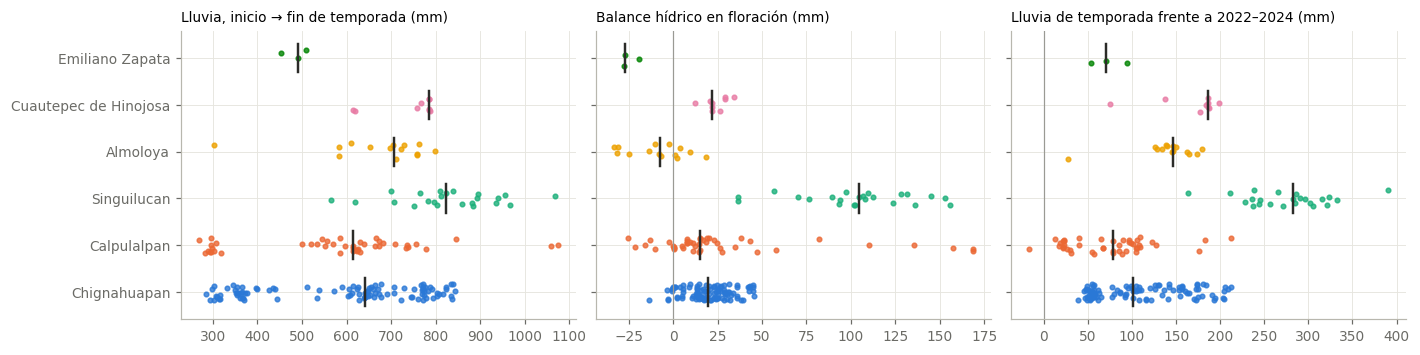

In [12]:
# 3.3 · Figura: lluvia de temporada y balance hídrico por municipio
top = plots.Municipio.value_counts().index[:6].tolist()
t = CLIM.join(plots.set_index("ID_POLIGONO").Municipio)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3), sharey=True)
for ax, (c, label) in zip(axes, [("clim_prec_season", "Lluvia, inicio → fin de temporada (mm)"),
                                 ("clim_wb_mid", "Balance hídrico en floración (mm)"),
                                 ("anom_clim_prec_season", "Lluvia de temporada frente a 2022–2024 (mm)")]):
    for k, m in enumerate(top):
        v = t.loc[t.Municipio == m, c].dropna()
        ax.scatter(v, np.full(len(v), k) + RNG.uniform(-0.18, 0.18, len(v)), s=9, color=MUNI_COLORS[k], alpha=0.8)
        ax.plot([v.median()] * 2, [k - 0.3, k + 0.3], color=INK, lw=1.6)
    ax.set_yticks(range(len(top))); ax.set_yticklabels(top)
    ax.set_title(label, loc="left", fontsize=9)
    if c.startswith("anom") or "_wb_" in c:
        ax.axvline(0, color=GREY, lw=0.8)
fig.tight_layout(); fig.savefig(FIG / "nb04_climate_by_municipality.png", bbox_inches="tight"); plt.show()

## 4 · Paso D: terreno

A partir del modelo de elevación del INEGI (píxeles de 120 m, metros, EPSG:6372) y del ráster de pendiente provisto:

| Variable | Significado |
|---|---|
| `topo_elev_mean`, `topo_elev_std` | elevación media y su dispersión dentro de la parcela (m) |
| `topo_slope_mean`, `topo_slope_std` | pendiente del ráster **provisto** (grados), omitiendo píxeles sin dato |
| `topo_slope_dem_mean` | pendiente **recalculada** desde el modelo de elevación con la misma malla de 120 m: un contraste y un respaldo donde el ráster provisto tiene huecos |
| `topo_northness`, `topo_eastness` | exposición: coseno y seno de la dirección de la pendiente, ponderados por su inclinación (una parcela plana da ≈ 0). Las laderas orientadas al norte reciben menos sol y conservan más humedad |
| `topo_tpi_1km`, `topo_tpi_4km` | posición topográfica: elevación de la parcela menos la elevación media del cuadrado de ~1 km / ~4 km que la rodea. Negativo = fondo de valle o depresión (acumula agua y aire frío); positivo = loma o cerro (drena, más expuesto) |
| `topo_slope_valid_share` | fracción de la parcela cubierta por píxeles válidos del ráster de pendiente provisto (calidad) |

**Pendiente y orientación desde la elevación.** Con la elevación *z* en una malla regular de 120 m, los gradientes ∂z/∂x (este) y ∂z/∂y (norte) son diferencias centrales. Pendiente = arctan(√(∂z/∂x² + ∂z/∂y²)); la dirección de la pendiente es el azimut del vector (−∂z/∂x, −∂z/∂y).

In [13]:
# 4.1 · Leer el terreno alrededor de las parcelas y derivar pendiente, exposición y posición topográfica
b = BOUNDS_MX
box = (b[0] - TOPO_BUFFER_M, b[1] - TOPO_BUFFER_M, b[2] + TOPO_BUFFER_M, b[3] + TOPO_BUFFER_M)
ELEV, GRID_T, e_epsg = read_raster(TOPO["elevation"], box)
SLOPE, GRID_S, s_epsg = read_raster(TOPO["slope"], box)
assert e_epsg == 6372 and s_epsg == 6372, f"se esperaba terreno en EPSG:6372 (se obtuvo {e_epsg}, {s_epsg})"
assert np.allclose(GRID_T, GRID_S) and ELEV.shape == SLOPE.shape, "las mallas de elevación y pendiente son distintas"
dx, dy = GRID_T[0], -GRID_T[2]
print(f"ventana de terreno {ELEV.shape}, píxel de {dx:.0f} × {dy:.0f} m")

gy_south, gx = np.gradient(ELEV, dy, dx)          # las filas aumentan hacia el sur
gn = -gy_south                                    # ∂z/∂north
SLOPE_DEM = np.degrees(np.arctan(np.hypot(gx, gn)))
aspect = np.arctan2(-gx, -gn)                     # azimut de la dirección de la pendiente, en sentido horario desde el norte
steep = np.sin(np.radians(SLOPE_DEM))
NORTH, EAST = np.cos(aspect) * steep, np.sin(aspect) * steep

def local_mean(z, k):
    ok = np.isfinite(z)
    num = ndimage.uniform_filter(np.where(ok, z, 0.0), size=2 * k + 1, mode="nearest")
    den = ndimage.uniform_filter(ok.astype(float), size=2 * k + 1, mode="nearest")
    return np.where(den > 0, num / np.maximum(den, 1e-12), np.nan)
TPI = {name: ELEV - local_mean(ELEV, k) for name, k in TPI_RADII_PX.items()}

COV_T = [coverage(r, GRID_T, ELEV.shape[1], ELEV.shape[0]) for r in RINGS_MX]
sums_t = np.array([w.sum() for _, _, w in COV_T])
check("Los pesos de cobertura de cada parcela suman 1 (malla de terreno)", bool(np.allclose(sums_t, 1, atol=1e-5)),
      f"mín {sums_t.min():.6f}; píxeles por parcela: mediana {np.median([len(w) for _, _, w in COV_T]):.0f}", warn_only=False)

def w_std(arr, cov):
    R, Cl, W = cov
    v = arr[R, Cl]; ok = np.isfinite(v)
    if ok.sum() < 2:
        return np.nan
    m = (W[ok] * v[ok]).sum() / W[ok].sum()
    return float(np.sqrt((W[ok] * (v[ok] - m) ** 2).sum() / W[ok].sum()))

TOPO_F = pd.DataFrame(index=pd.Index(IDS, name="ID_POLIGONO"))
recs = []
for pid, cov in zip(IDS, COV_T):
    r = {}
    r["topo_elev_mean"], _ = weighted(ELEV, cov)
    r["topo_elev_std"] = w_std(ELEV, cov)
    r["topo_slope_mean"], r["topo_slope_valid_share"] = weighted(SLOPE, cov)
    r["topo_slope_std"] = w_std(SLOPE, cov)
    r["topo_slope_dem_mean"], _ = weighted(SLOPE_DEM, cov)
    r["topo_northness"], _ = weighted(NORTH, cov)
    r["topo_eastness"], _ = weighted(EAST, cov)
    for name, arr in TPI.items():
        r[f"topo_{name}"], _ = weighted(arr, cov)
    recs.append(r)
TOPO_F = pd.DataFrame(recs, index=TOPO_F.index)
for c, (dsc, unit) in {"topo_elev_mean": ("elevación media", "m"), "topo_elev_std": ("dispersión de la elevación dentro de la parcela", "m"),
                       "topo_slope_mean": ("pendiente media, ráster provisto", "degrees"), "topo_slope_std": ("dispersión de la pendiente, ráster provisto", "degrees"),
                       "topo_slope_dem_mean": ("pendiente media recalculada desde la elevación", "degrees"),
                       "topo_northness": ("exposición norte (cos orientación × sen pendiente)", "-1…1"),
                       "topo_eastness": ("exposición este (sen orientación × sen pendiente)", "-1…1"),
                       "topo_tpi_1km": ("elevación menos la media del cuadrado de ~1 km", "m"),
                       "topo_tpi_4km": ("elevación menos la media del cuadrado de ~4 km", "m")}.items():
    register(c, "terrain", "INEGI CEM 4.0", c.split("_")[1], "static", "area-weighted", dsc, unit)
register("topo_slope_valid_share", "quality", "INEGI CEM 4.0", "slope", "static", "share",
         "fracción de la parcela en píxeles válidos del ráster de pendiente provisto", "0–1", use=False)
display(TOPO_F.describe().round(2).T)

ventana de terreno (513, 440), píxel de 120 × 120 m
[PASS] Los pesos de cobertura de cada parcela suman 1 (malla de terreno) — mín 1.000000; píxeles por parcela: mediana 10
                        count     mean    std      min      25%      50%      75%      max
topo_elev_mean          197.0  2667.10  92.28  2496.65  2611.35  2638.90  2726.68  2906.04
topo_elev_std           196.0     4.11   3.04     0.00     1.51     3.09     6.28    15.72
topo_slope_mean         197.0     2.79   2.05     0.28     1.15     2.13     3.89     9.40
topo_slope_valid_share  197.0     0.99   0.09     0.02     1.00     1.00     1.00     1.00
topo_slope_std          196.0     0.69   0.71     0.02     0.18     0.42     0.85     3.16
topo_slope_dem_mean     197.0     2.88   2.13     0.27     1.12     2.20     4.05     9.37
topo_northness          197.0    -0.00   0.04    -0.16    -0.02     0.00     0.02     0.13
topo_eastness           197.0    -0.00   0.04    -0.14    -0.01     0.00     0.02     0.10
topo_tpi

[PASS] La pendiente provista coincide con la recalculada desde la elevación (r ≥ 0.9) — r = 0.996; diferencia mediana -0.04°
[INFO] Parcelas parcialmente en píxeles de pendiente sin dato — 5 parcela(s): AGC_020 (65 % válido), AGC_023 (29 % válido), AGC_044 (98 % válido), AGC_164 (55 % válido), AGC_170 (2 % válido)
[PASS] Todas las parcelas tienen pendiente (huecos rellenados con la pendiente recalculada) — 0 rellenadas
[WARN] Variables de terreno completas — 2 valores faltantes (slope_std necesita ≥ 2 píxeles válidos)


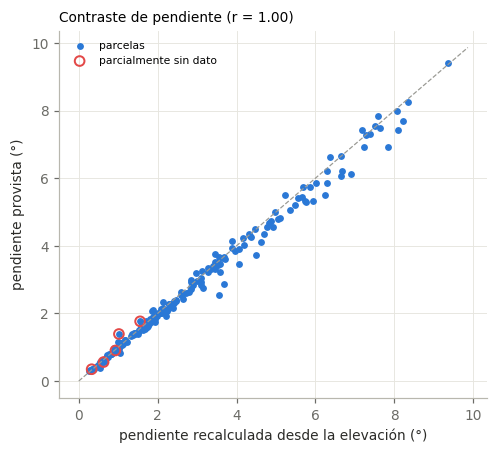

In [14]:
# 4.2 · Contrastar la pendiente provista con la recalculada desde la elevación; rellenar huecos
r = TOPO_F[["topo_slope_mean", "topo_slope_dem_mean"]].corr().iloc[0, 1]
gaps = TOPO_F.index[TOPO_F.topo_slope_valid_share < 0.999].tolist()
check("La pendiente provista coincide con la recalculada desde la elevación (r ≥ 0.9)", r >= 0.9,
      f"r = {r:.3f}; diferencia mediana {np.nanmedian(TOPO_F.topo_slope_mean - TOPO_F.topo_slope_dem_mean):+.2f}°")
check("Parcelas parcialmente en píxeles de pendiente sin dato", True,
      f"{len(gaps)} parcela(s): " + ", ".join(f"{p} ({100 * TOPO_F.loc[p, 'topo_slope_valid_share']:.0f} % válido)" for p in gaps[:8]), info=True)
missing_slope = TOPO_F.topo_slope_mean.isna()
TOPO_F.loc[missing_slope, "topo_slope_mean"] = TOPO_F.loc[missing_slope, "topo_slope_dem_mean"]
check("Todas las parcelas tienen pendiente (huecos rellenados con la pendiente recalculada)", bool(TOPO_F.topo_slope_mean.notna().all()),
      f"{int(missing_slope.sum())} rellenadas")
check("Variables de terreno completas", bool(TOPO_F.drop(columns="topo_slope_std").notna().all().all()),
      f"{int(TOPO_F.isna().sum().sum())} valores faltantes (slope_std necesita ≥ 2 píxeles válidos)")

fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.scatter(TOPO_F.topo_slope_dem_mean, TOPO_F.topo_slope_mean, s=12, color="#2a78d6", label="parcelas")
if gaps:
    ax.scatter(TOPO_F.loc[gaps, "topo_slope_dem_mean"], TOPO_F.loc[gaps, "topo_slope_mean"], s=40, facecolors="none",
               edgecolors=RED, lw=1.3, label="parcialmente sin dato")
lim = [0, max(TOPO_F.topo_slope_dem_mean.max(), TOPO_F.topo_slope_mean.max()) * 1.05]
ax.plot(lim, lim, color=GREY, lw=0.8, ls="--")
ax.set_xlabel("pendiente recalculada desde la elevación (°)"); ax.set_ylabel("pendiente provista (°)")
ax.set_title(f"Contraste de pendiente (r = {r:.2f})", loc="left", fontsize=9); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "nb04_slope_check.png", bbox_inches="tight"); plt.show()

## 5 · Paso E: integrar, documentar y primera mirada descriptiva

Como en el cuaderno 03: no se imputa nada (eso ocurre dentro de los pliegues de validación cruzada), las variables de calidad se marcan con `use_in_model = False` y la mirada al rendimiento es solo descriptiva: parcelas de entrenamiento, ρ de Spearman global y dentro de municipio; |ρ| ≈ 0.17 es aproximadamente el umbral de significancia con 138 parcelas.

In [15]:
# 5.1 · Guardado, catálogo, correlaciones descriptivas y reporte
assert len(CLIM) == len(TOPO_F) == len(IDS)
CLIM.reset_index().to_parquet(FEATURES / "climate_features.parquet", index=False)
TOPO_F.reset_index().to_parquet(FEATURES / "topo_features.parquet", index=False)
cat = pd.DataFrame(CATALOG).drop_duplicates("feature").set_index("feature")
ALL = CLIM.join(TOPO_F)
cat["kept"] = True
cat["missing_%"] = (100 * ALL.isna().mean()).reindex(cat.index).round(2)
cat.to_csv(FEATURES / "feature_catalog_nb04.csv")

lab = pd.read_parquet(INTERIM / "labels.parquet").set_index("ID_POLIGONO")
tr = ALL.join(lab[["RENDIMIENTO_T_HA", "is_train"]]).join(plots.set_index("ID_POLIGONO").Municipio)
tr = tr[tr.is_train]
num = [c for c in ALL.columns if cat.loc[c, "use_in_model"] and ALL[c].nunique() > 2]
overall = tr[num].corrwith(tr.RENDIMIENTO_T_HA, method="spearman")
dm = tr[num + ["RENDIMIENTO_T_HA"]].sub(tr.groupby("Municipio")[num + ["RENDIMIENTO_T_HA"]].transform("mean"))
within = dm[num].corrwith(dm.RENDIMIENTO_T_HA, method="spearman")
look = pd.DataFrame({"overall": overall, "within_municipality": within}).join(cat[["group"]])
look = look.reindex(look.within_municipality.abs().sort_values(ascending=False).index)
look.to_csv(QA / "nb04_descriptive_correlations.csv")
display(look.head(15).round(3))
check("Descriptivo: variables de clima y terreno con |ρ| ≥ 0.17 dentro de municipio", True,
      f"{int((look.within_municipality.abs() >= 0.17).sum())} de {len(look)}; la más fuerte: {look.index[0]} "
      f"(ρ = {look.within_municipality.iloc[0]:+.2f}); la más fuerte en global: {look.overall.abs().idxmax()} "
      f"(ρ = {look.overall[look.overall.abs().idxmax()]:+.2f})", info=True)

def md_table(df):
    df = df.copy()
    cols = [str(c) for c in df.columns]
    out = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for _, r in df.iterrows():
        out.append("| " + " | ".join("" if pd.isna(v) else (f"{v:.4g}" if isinstance(v, float) else str(v)) for v in r.values) + " |")
    return "\n".join(out)

chk = pd.DataFrame(CHECKS)
lines = ["# Reporte del cuaderno 04: clima y topografía por polígono",
         f"Generado {datetime.now():%Y-%m-%d %H:%M} · Colab: {IN_COLAB}", "",
         f"**Conteo de estados:** {chk.status.value_counts().to_dict()}", "",
         "## Verificaciones", md_table(chk), "",
         "## Precipitación mensual, mediana de las parcelas (mm)", md_table(tab.reset_index()), "",
         "## Clima en la temporada (por parcela)", md_table(CLIM[[c for c in CLIM.columns if c.endswith("_season") and not c.startswith("anom")]].describe().round(1).T.reset_index()), "",
         "## Terreno", md_table(TOPO_F.describe().round(2).T.reset_index()), "",
         "## Correlaciones descriptivas con el rendimiento (parcelas de entrenamiento; 20 primeras por |ρ| dentro de municipio)",
         md_table(look.head(20).round(3).reset_index().rename(columns={"index": "feature"}))]
(QA / "nb04_report.md").write_text("\n".join(lines), encoding="utf-8")
print(chk.status.value_counts().to_dict())
problems = chk[chk.status.isin(["WARN", "FAIL"])]
display(problems if len(problems) else "Todas las verificaciones pasaron.")
print(f"Reporte: {QA / 'nb04_report.md'}")

                      overall  within_municipality            group
clim_tmax_mid          -0.226               -0.240          climate
clim_pet_mid           -0.322               -0.234          climate
clim_tmean_mid          0.084               -0.233          climate
clim_gdd_mid            0.084               -0.233          climate
clim_tmax_late         -0.513               -0.229          climate
clim_pet_cycle         -0.693               -0.226          climate
clim_gdd_late           0.081               -0.223          climate
clim_tmean_late        -0.063               -0.220          climate
clim_pet_late          -0.020               -0.218          climate
anom_clim_amp_season    0.205                0.215  climate anomaly
clim_prec_late         -0.065               -0.212          climate
topo_slope_dem_mean     0.241                0.211          terrain
clim_tmax_season       -0.400               -0.206          climate
clim_tmean_season       0.105               -0.2